<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Trading data analysis comparing stock prices

In [ ]:
#importing  the dataset
data= pd.read_csv("/content/drive/MyDrive/assignment3_stock_prices (1).csv")
X= data.iloc[:,:-1].values
Y = data.iloc[:,1].values


In [ ]:
#viewing first 10 rows
data.head(10)

,Day,Opening_Price,High_Price,Low_Price,Volume,Closing_Price
0,1,102.48,109.84,100.45,476836,104.19
1,2,99.65,104.88,96.68,187235,100.09
2,3,103.91,110.76,98.62,297484,107.43
3,4,108.63,116.00,102.48,289407,110.22
4,5,100.18,104.09,94.27,311810,102.42
5,6,100.51,103.18,97.17,303687,105.94
6,7,109.92,113.29,103.65,173523,110.60
7,8,106.20,110.76,102.77,336175,105.38
8,9,100.35,107.26,96.40,194476,101.69
9,10,105.75,112.91,99.27,333841,109.16


In [ ]:
#checking data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Day            90 non-null     int64  
 1   Opening_Price  90 non-null     float64
 2   High_Price     90 non-null     float64
 3   Low_Price      90 non-null     float64
 4   Volume         90 non-null     int64  
 5   Closing_Price  90 non-null     float64
dtypes: float64(4), int64(2)
memory usage: 4.3 KB


In [ ]:
#Checking data statistical description
data.describe()

,Day,Opening_Price,High_Price,Low_Price,Volume,Closing_Price
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,45.500000,114.506111,119.448667,109.313444,295940.688889,114.662222
std,26.124701,10.234127,10.494967,10.384641,120232.475035,10.658855
min,1.000000,94.820000,98.150000,89.410000,105237.000000,92.210000
25%,23.250000,106.005000,110.775000,100.582500,189045.250000,105.957500
50%,45.500000,114.135000,119.330000,108.420000,293982.000000,115.070000
75%,67.750000,123.907500,127.755000,117.790000,400286.750000,121.652500
max,90.000000,135.030000,140.880000,132.850000,497827.000000,138.340000


In [ ]:
#checking for null values
data.isna().sum()

,0
Day,0
Opening_Price,0
High_Price,0
Low_Price,0
Volume,0
Closing_Price,0


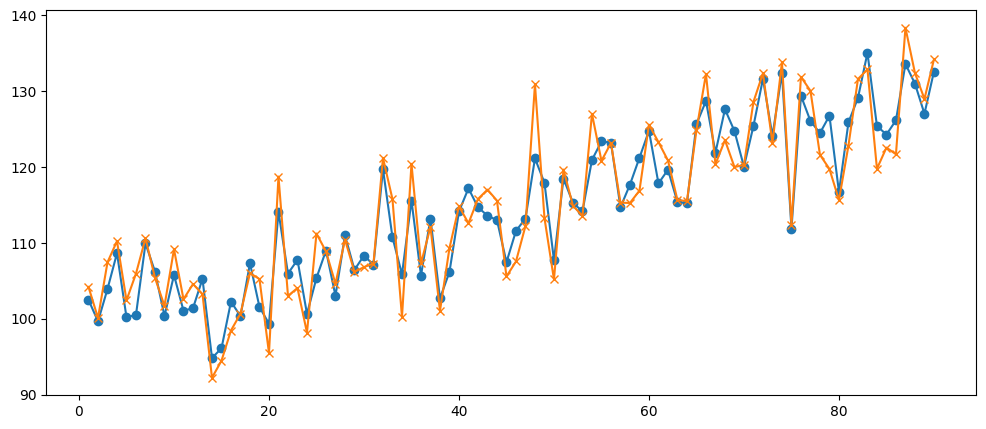

In [ ]:
#Create time series plot showing opening and closing prices over time
plt.figure(figsize=(12,5))
plt.plot(data["Day"], data["Opening_Price"], label="Opening Price", marker='o')
plt.plot(data["Day"], data["Closing_Price"], label="Closing Price", marker='x')

plt.xlabel("Day")
plt.ylabel("Price")
plt.title("Opening and Closing Prices Over Time")
plt.legend()
plt.show()

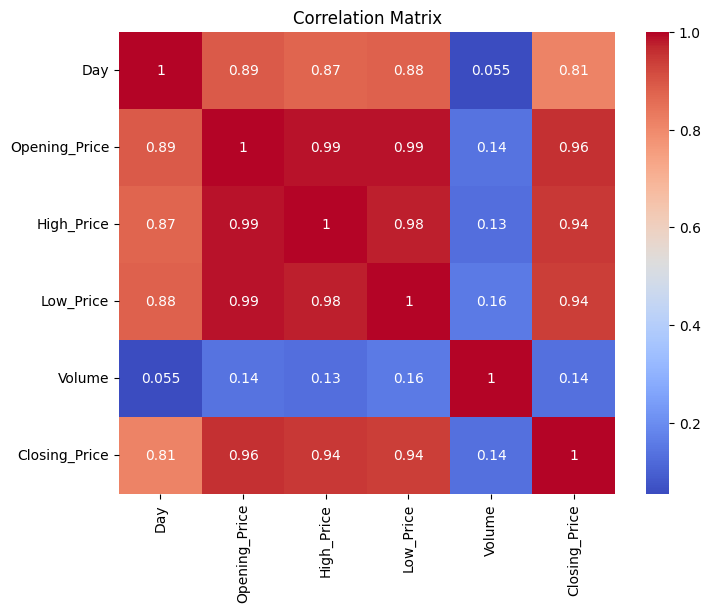

In [ ]:
#Calculating and display correlation matrix
import seaborn as sns

# Correlation matrix
corr_matrix = data.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
#Identify which features are most correlated with closing price
# Correlation with target
corr_with_closing = corr_matrix["Closing_Price"].sort_values(ascending=False)

print("Features most correlated with Closing Price:")
print(corr_with_closing)

Features most correlated with Closing Price:
Closing_Price    1.000000
Opening_Price    0.956196
High_Price       0.944826
Low_Price        0.938813
Day              0.814287
Volume           0.135048
Name: Closing_Price, dtype: float64


In [ ]:
### Feature engineering
# Creating new features
data["Price_Range"] = data["High_Price"] - data["Low_Price"]

# Shifting PriceChange by 1 day to avoid data leakage
data["Price_Change"] = (data["Closing_Price"] - data["Opening_Price"]).shift(1)

# Moving average of Volume (window = 5)
data["Volume_MA"] = data["Volume"].rolling(window=5).mean()

# Handling NaN values created by shifting and rolling
data = data.dropna().reset_index(drop=True)

data.head()

,Day,Opening_Price,High_Price,Low_Price,Volume,Closing_Price,Price_Range,Price_Change,Volume_MA
0,5,100.18,104.09,94.27,311810,102.42,9.82,1.59,312554.4
1,6,100.51,103.18,97.17,303687,105.94,6.01,2.24,277924.6
2,7,109.92,113.29,103.65,173523,110.60,9.64,5.43,275182.2
3,8,106.20,110.76,102.77,336175,105.38,7.99,0.68,282920.4
4,9,100.35,107.26,96.40,194476,101.69,10.86,-0.82,263934.2


In [ ]:
#data preparation
# Defining feature sets
original_features = ["Opening_Price", "High_Price", "Low_Price", "Volume"]
engineered_features = original_features + ["Price_Range", "Price_Change", "Volume_MA"]

X = data[engineered_features]
y = data["Closing_Price"]

# Time series split: first 70 days train, last 20 days test
X_train = X.iloc[:70]
X_test = X.iloc[70:]

y_train = y.iloc[:70]
y_test = y.iloc[70:]

In [ ]:
#creating models starting with Model 1: Multiple Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Initializing the model
mlr_model = LinearRegression()

# Training the model on training data
mlr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
#creating the predictions for the closing prices
y_pred_mlr = mlr_model.predict(X_test)
print(y_pred_mlr)

[111.53074771 129.82708478 125.89258043 123.79066884 127.26249445
 117.58250539 126.28501393 130.14306722 135.98841623 125.81641926
 124.88316754 126.42942642 133.73143264 129.86765878 127.10614028
 133.4090044 ]


In [ ]:
#claculating metric

r2_mlr = r2_score(y_test, y_pred_mlr)
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)
rmse_mlr = np.sqrt(mean_squared_error(y_test, y_pred_mlr))

# Displaying results
print("Multiple Linear Regression Results")
print(f"R² Score : {r2_mlr}")
print(f"MAE      : {mae_mlr}")
print(f"RMSE     : {rmse_mlr}")

Multiple Linear Regression Results
R² Score : 0.7492726955655423
MAE      : 3.102524737952532
RMSE     : 3.6023286290448002


In [ ]:
#creating the polynomial 2 degree model
from sklearn.preprocessing import PolynomialFeatures

# Initializing the polynomial feature transformer
poly2 = PolynomialFeatures(degree=2, include_bias=False)

# Transform training and testing data
X_train_poly = poly2.fit_transform(X_train)
X_test_poly = poly2.transform(X_test)

In [ ]:
# Initializing model
poly_model = LinearRegression()

# Train model
poly_model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
#making the predictions
y_pred_poly = poly_model.predict(X_test_poly)
print(y_pred_poly)

[110.48630498 129.96260635 125.12786247 123.72201701 123.89764086
 110.7353637  124.72125364 128.6084796  138.48751154 126.80407627
 125.13592184 124.61774073 131.86053742 131.03677062 128.87046955
 133.14219532]


In [ ]:
#calculating the metrics
r2_poly = r2_score(y_test, y_pred_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))

# Display results
print("Polynomial Regression (Degree 2) Results")
print(f"R² Score : {r2_poly}")
print(f"MAE      : {mae_poly}")
print(f"RMSE     : {rmse_poly}")

Polynomial Regression (Degree 2) Results
R² Score : 0.7207381033717921
MAE      : 3.2465982420871073
RMSE     : 3.801792025771307


In [ ]:
#comparing the two models using r2 results
print("\nModel Comparison")
print(f"Linear Regression  R²: {r2_mlr}")
print(f"Polynomial Reg.    R²: {r2_poly}")


Model Comparison
Linear Regression  R²: 0.7492726955655423
Polynomial Reg.    R²: 0.7207381033717921


In [ ]:
#creating the decision tree regressor
from sklearn.tree import DecisionTreeRegressor
#defining the depths
depths = [3, 5, 7, 10]
dt_results = {}

for depth in depths:
    # Initializing the model
    dt_model = DecisionTreeRegressor(max_depth=depth, random_state=42)

    # Train
    dt_model.fit(X_train, y_train)

    # Predicting
    y_pred_dt = dt_model.predict(X_test)

    # Metrics
    r2 = r2_score(y_test, y_pred_dt)
    mae = mean_absolute_error(y_test, y_pred_dt)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_dt))

    # Store results
    dt_results[depth] = {
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "model": dt_model
    }

    # Display results
    print(f"\nDecision Tree (max_depth={depth})")
    print(f"R²   : {r2}")
    print(f"MAE  : {mae}")
    print(f"RMSE : {rmse}")



Decision Tree (max_depth=3)
R²   : 0.7510685087143889
MAE  : 2.6751712740384512
RMSE : 3.5894047585970883

Decision Tree (max_depth=5)
R²   : 0.7133942430098866
MAE  : 3.136946022727269
RMSE : 3.8514562476962375

Decision Tree (max_depth=7)
R²   : 0.6388562765410897
MAE  : 3.169999999999998
RMSE : 4.323371441942041

Decision Tree (max_depth=10)
R²   : 0.5898652523962506
MAE  : 3.356562499999999
RMSE : 4.607292622842617


In [ ]:
# Selecting the model with highest R²
best_depth = max(dt_results, key=lambda d: dt_results[d]["R2"])
best_dt_model = dt_results[best_depth]["model"]

print(f"\nBest max_depth based on R²: {best_depth}")


Best max_depth based on R²: 3


In [ ]:
# Extracting feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_dt_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(feature_importance)

         Feature  Importance
1     High_Price    0.856732
0  Opening_Price    0.070205
2      Low_Price    0.065340
5   Price_Change    0.007723
3         Volume    0.000000
4    Price_Range    0.000000
6      Volume_MA    0.000000


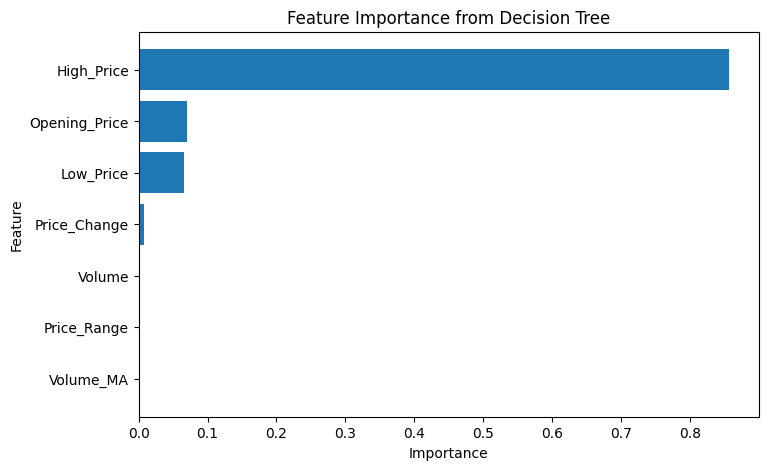

In [ ]:
plt.figure(figsize=(8,5))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance from Decision Tree")
plt.gca().invert_yaxis()
plt.show()

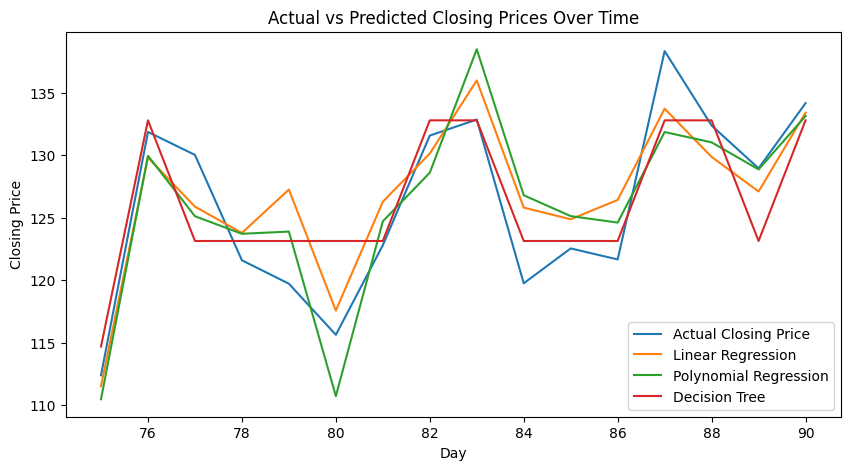

In [ ]:
# Predicting using best Decision Tree (use your selected best_depth)
y_pred_dt = best_dt_model.predict(X_test)

# Time index for test set
time_index = data["Day"].iloc[-len(y_test):]

plt.figure(figsize=(10,5))
plt.plot(time_index, y_test, label="Actual Closing Price")
plt.plot(time_index, y_pred_mlr, label="Linear Regression")
plt.plot(time_index, y_pred_poly, label="Polynomial Regression")
plt.plot(time_index, y_pred_dt, label="Decision Tree")

plt.xlabel("Day")
plt.ylabel("Closing Price")
plt.title("Actual vs Predicted Closing Prices Over Time")
plt.legend()
plt.show()

The visualization results show that all models generally follow the overall trend of the actual closing prices, but with varying levels of accuracy. The Multiple Linear Regression predictions appear smoother and often underreact to sharp price movements, indicating its limitation in capturing non-linear behavior. Polynomial Regression tracks the actual prices more closely, especially during moderate fluctuations, but shows larger deviations at certain points, suggesting increased variance. The Decision Tree model aligns most closely with the actual closing prices, particularly during rapid changes, demonstrating its ability to capture non-linear patterns. The comparison table of evaluation metrics confirms this visual observation, with the Decision Tree achieving the highest R² and lowest error values. Residual plots further support these findings: Linear Regression residuals display systematic patterns (model bias), Polynomial Regression residuals show increased spread over time, and the Decision Tree residuals are more randomly distributed, indicating a better overall fit to the data

Based on the evaluation metrics on the test set, the Decision Tree Regression model with an optimized max_depth performed best overall, achieving the highest R² score and the lowest error values compared to Multiple Linear Regression and Polynomial Regression. While Polynomial Regression improved upon the linear baseline by capturing some non-linear patterns, it showed signs of increased variance, highlighting the risk of overfitting, especially with limited time-series data. Decision Trees, although more flexible, can also overfit if the tree depth is too large, which is why controlling max_depth is critical. A key limitation of using regression models for stock price prediction is that they rely heavily on historical price relationships and assume patterns will persist, which is often unrealistic in highly volatile and event-driven financial markets. Additionally, these models do not account for external factors such as market sentiment, macroeconomic indicators, company news, or geopolitical events. Incorporating features like technical indicators (e.g., moving averages, RSI), broader market indices, sentiment analysis from news or social media, and longer historical data could significantly improve predictive performance. Despite providing useful insights for trend analysis and educational purposes, these regression models are not recommended for real-world trading decisions, as they lack robustness to sudden market changes and do not model risk, transaction costs, or uncertainty adequately.